In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import TruncatedSVD

ratings = pd.read_csv("../data/ratings_clean.csv")
books = pd.read_csv("../data/books_clean.csv")
tags = pd.read_csv("../data/tags.csv")
book_tags = pd.read_csv("../data/book_tags.csv")

print("Ratings:", ratings.shape, "| Books:", books.shape)
print("Books columns:", books.columns.tolist())

Ratings: (493250, 3) | Books: (9989, 8)
Books columns: ['book_id', 'title', 'authors', 'original_publication_year', 'average_rating', 'ratings_count', 'language_code', 'image_url']


In [8]:
train, test = train_test_split(ratings, test_size=0.2, random_state=42)

# Convert IDs to indexes 0, 1, 2... (needed for building matrices)
user_ids = ratings["user_id"].unique()
book_ids = books["book_id"].unique()
user2idx = {u: i for i, u in enumerate(user_ids)}
book2idx = {b: i for i, b in enumerate(book_ids)}
idx2book = {i: b for b, i in book2idx.items()}
book_title = dict(zip(books["book_id"], books["title"]))

train = train[train["book_id"].isin(book2idx)].copy()
test = test[test["book_id"].isin(book2idx)].copy()
train["u"] = train["user_id"].map(user2idx)
train["b"] = train["book_id"].map(book2idx)

n_users, n_books = len(user_ids), len(book_ids)
print("Train:", train.shape, "| Test:", test.shape)
print("Users:", n_users, "| Books:", n_books)

# Helper: search a book by title
def find_book(query):
    m = books[books["title"].str.contains(query, case=False, regex=False)]
    return m[["book_id", "title", "authors"]].head(5)

Train: (394600, 5) | Test: (98650, 3)
Users: 10000 | Books: 9989


In [9]:
#Cell 3: MODEL 1, Popularity-Based (Baseline)
stats = train.groupby("book_id")["rating"].agg(["mean", "count"]).reset_index()
C = stats["mean"].mean()                 # global average rating
m = stats["count"].quantile(0.70)        # minimum votes threshold

# Weighted rating (IMDB formula)
stats["score"] = (stats["count"] / (stats["count"] + m)) * stats["mean"] + \
                 (m / (stats["count"] + m)) * C
popularity = stats.sort_values("score", ascending=False)

def recommend_popular(n=10):
    top = popularity.head(n).merge(books[["book_id", "title", "authors"]], on="book_id")
    return top[["title", "authors", "mean", "count", "score"]]

recommend_popular(10)

,title,authors,mean,count,score
0,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.754386,57,4.327280
1,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.866667,45,4.326523
2,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.769231,52,4.314041
3,The Doll's House (The Sandman #2),"Neil Gaiman, Steve Parkhouse, Chris Bachalo, M...",4.682540,63,4.310055
4,The Kindly Ones (The Sandman #9),"Neil Gaiman, Marc Hempel, Richard Case, D'Isra...",4.700000,60,4.309426
5,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.714286,56,4.302301
6,"Saga, Vol. 2 (Saga, #2)","Brian K. Vaughan, Fiona Staples",4.800000,45,4.295273
7,Calvin and Hobbes,"Bill Watterson, G.B. Trudeau",4.703704,54,4.289012
8,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.790698,43,4.280279
9,The Stand: Soul Survivors,"Roberto Aguirre-Sacasa, Mike Perkins, Laura ...",4.744681,47,4.279043


In [10]:
# Tags that carry no information about the book itself
junk_tags = {"to-read", "currently-reading", "favorites", "owned", "books-i-own",
             "default", "library", "kindle", "ebook", "audiobook", "wish-list",
             "my-books", "owned-books", "to-buy", "favourites", "e-book", "read"}

id_col = "goodreads_book_id" if "goodreads_book_id" in books.columns else "book_id"
overlap = books[id_col].isin(book_tags["goodreads_book_id"]).sum()
print(f"Tag join column: {id_col} | matching books: {overlap}")

books["tag_text"] = ""
if overlap > 0:
    bt = book_tags.merge(tags, on="tag_id")
    bt = bt[~bt["tag_name"].isin(junk_tags)]
    bt = bt.sort_values("count", ascending=False).groupby("goodreads_book_id").head(10)
    tag_str = bt.groupby("goodreads_book_id")["tag_name"].apply(lambda x: " ".join(x))
    books["tag_text"] = books[id_col].map(tag_str).fillna("")

books["content"] = (books["title"].fillna("") + " " +
                    books["authors"].fillna("") + " " +
                    books["tag_text"])

tfidf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(books["content"])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

def recommend_content(book_query, n=10):
    match = books[books["title"].str.contains(book_query, case=False, regex=False)]
    if match.empty:
        return "Book not found. Use find_book('...') to search the title."
    i = match.index[0]
    sims = linear_kernel(tfidf_matrix[i], tfidf_matrix).flatten()
    top = sims.argsort()[::-1][1:n+1]
    out = books.iloc[top][["title", "authors"]].copy()
    out["similarity"] = sims[top].round(3)
    print("Because you liked:", books.iloc[i]["title"])
    return out

recommend_content("Harry Potter and the Sorcerer", 5)

Tag join column: book_id | matching books: 812
TF-IDF matrix shape: (9989, 20000)
Because you liked: Harry Potter and the Sorcerer's Stone (Harry Potter, #1)


,title,authors,similarity
3273,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",0.647
2099,"The Harry Potter Collection 1-4 (Harry Potter,...","J.K. Rowling, Mary GrandPré",0.637
17,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.636
421,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,0.625
22,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.618


In [11]:
# Item x User sparse matrix (rows = books, columns = users)
item_user = csr_matrix((train["rating"].values, (train["b"].values, train["u"].values)),
                       shape=(n_books, n_users))

knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=21)
knn.fit(item_user)

def similar_books_cf(book_query, n=10):
    match = books[books["title"].str.contains(book_query, case=False, regex=False)]
    if match.empty:
        return "Book not found."
    bid = match.iloc[0]["book_id"]
    dist, ind = knn.kneighbors(item_user[book2idx[bid]], n_neighbors=n+1)
    out = pd.DataFrame({
        "title": [book_title[idx2book[i]] for i in ind[0][1:]],
        "similarity": (1 - dist[0][1:]).round(3)})
    print("Readers who liked:", book_title[bid])
    return out

def recommend_cf_for_user(user_id, n=10):
    u = user2idx[user_id]
    seen = set(train.loc[train["u"] == u, "b"])
    liked = train[(train["u"] == u) & (train["rating"] >= 4)]["b"].tolist()[:20]
    scores = {}
    for b in liked:
        dist, ind = knn.kneighbors(item_user[b], n_neighbors=21)
        for d, j in zip(dist[0][1:], ind[0][1:]):
            if j not in seen:
                scores[j] = scores.get(j, 0) + (1 - d)
    top = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:n]
    return pd.DataFrame({"title": [book_title[idx2book[j]] for j, _ in top],
                         "score": [round(s, 3) for _, s in top]})

print(similar_books_cf("Harry Potter and the Sorcerer", 5))
print()
print(recommend_cf_for_user(user_ids[0], 5))

Readers who liked: Harry Potter and the Sorcerer's Stone (Harry Potter, #1)
                                               title  similarity
0                                          Jane Eyre       0.517
1                          The Diary of a Young Girl       0.499
2  Harry Potter and the Goblet of Fire (Harry Pot...       0.493
3  Harry Potter and the Chamber of Secrets (Harry...       0.488
4                                    The Kite Runner       0.452

                       title  score
0          The Secret Garden  1.246
1        Memoirs of a Geisha  1.228
2  The Diary of a Young Girl  1.157
3                 Life of Pi  0.983
4          Lord of the Flies  0.972


In [12]:
# Subtract each user's mean rating (mean-centering)
user_mean = train.groupby("u")["rating"].mean()
train["centered"] = train["rating"] - train["u"].map(user_mean)

user_item = csr_matrix((train["centered"].values, (train["u"].values, train["b"].values)),
                       shape=(n_users, n_books))

svd = TruncatedSVD(n_components=50, random_state=42)
user_factors = svd.fit_transform(user_item)      # (users x 50)
item_factors = svd.components_                   # (50 x books)
print("Explained variance:", round(svd.explained_variance_ratio_.sum(), 3))

global_mean = train["rating"].mean()
user_mean_arr = np.full(n_users, global_mean)
user_mean_arr[user_mean.index.values] = user_mean.values

def recommend_svd_for_user(user_id, n=10):
    u = user2idx[user_id]
    pred = user_mean_arr[u] + user_factors[u] @ item_factors
    seen = set(train.loc[train["u"] == u, "b"])
    order = [j for j in pred.argsort()[::-1] if j not in seen][:n]
    return pd.DataFrame({"title": [book_title[idx2book[j]] for j in order],
                         "predicted_rating": np.clip(pred[order], 1, 5).round(2)})

recommend_svd_for_user(user_ids[0], 5)

Explained variance: 0.053


,title,predicted_rating
0,The Shipping News,3.80
1,The Shadow of the Wind (The Cemetery of Forgot...,3.80
2,A Prayer for Owen Meany,3.79
3,The Giving Tree,3.79
4,"The Amber Spyglass (His Dark Materials, #3)",3.78


In [13]:
uid = user_ids[0]
print("USER:", uid)
print("\n--- Popularity ---");   print(recommend_popular(5)[["title"]].to_string(index=False))
print("\n--- Item-Item CF ---"); print(recommend_cf_for_user(uid, 5)[["title"]].to_string(index=False))
print("\n--- SVD ---");          print(recommend_svd_for_user(uid, 5)[["title"]].to_string(index=False))

USER: 314

--- Popularity ---
                                                     title
A Court of Mist and Fury (A Court of Thorns and Roses, #2)
  The Days Are Just Packed: A Calvin and Hobbes Collection
      It's a Magical World: A Calvin and Hobbes Collection
                         The Doll's House (The Sandman #2)
                          The Kindly Ones (The Sandman #9)

--- Item-Item CF ---
                    title
        The Secret Garden
      Memoirs of a Geisha
The Diary of a Young Girl
               Life of Pi
        Lord of the Flies

--- SVD ---
                                                        title
                                            The Shipping News
The Shadow of the Wind (The Cemetery of Forgotten Books,  #1)
                                      A Prayer for Owen Meany
                                              The Giving Tree
                  The Amber Spyglass (His Dark Materials, #3)


In [14]:
# Index columns for the test data
test["u"] = test["user_id"].map(user2idx)
test["b"] = test["book_id"].map(book2idx)
test = test.dropna(subset=["u", "b"]).copy()
test["u"] = test["u"].astype(int)
test["b"] = test["b"].astype(int)
y_true = test["rating"].values

global_mean = train["rating"].mean()
item_mean = train.groupby("b")["rating"].mean()
item_mean_arr = np.full(n_books, global_mean)
item_mean_arr[item_mean.index.values] = item_mean.values

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def mae(y, p):  return float(np.mean(np.abs(y - p)))

u_arr, b_arr = test["u"].values, test["b"].values

# Model 1: Popularity baseline (item average rating)
pred_pop = item_mean_arr[b_arr]

# Model 3: Item-Item KNN
dist_all, ind_all = knn.kneighbors(item_user, n_neighbors=21)
sim_all = 1 - dist_all
user_rated = {u: dict(zip(g["b"], g["rating"])) for u, g in train.groupby("u")}

def predict_knn(u, b):
    rated = user_rated.get(u, {})
    num = den = 0.0
    for j, s in zip(ind_all[b], sim_all[b]):
        if j != b and j in rated:
            num += s * rated[j]
            den += s
    return num / den if den > 0 else item_mean_arr[b]

pred_knn = np.array([predict_knn(u, b) for u, b in zip(u_arr, b_arr)])

# Model 4: SVD
pred_svd = user_mean_arr[u_arr] + np.sum(user_factors[u_arr] * item_factors.T[b_arr], axis=1)
pred_svd = np.clip(pred_svd, 1, 5)

rating_results = pd.DataFrame({
    "Model": ["Popularity (Item Mean)", "Item-Item KNN", "SVD"],
    "RMSE": [rmse(y_true, pred_pop), rmse(y_true, pred_knn), rmse(y_true, pred_svd)],
    "MAE":  [mae(y_true, pred_pop),  mae(y_true, pred_knn),  mae(y_true, pred_svd)],
}).round(4)
rating_results

,Model,RMSE,MAE
0,Popularity (Item Mean),0.9549,0.7669
1,Item-Item KNN,0.8839,0.6218
2,SVD,0.8503,0.6597


In [15]:
K, LIKE = 10, 4          # a book rated 4 or higher counts as "relevant"
rng = np.random.RandomState(42)

relevant    = test[test["rating"] >= LIKE].groupby("u")["b"].apply(set).to_dict()
train_seen  = train.groupby("u")["b"].apply(set).to_dict()
train_liked = train[train["rating"] >= LIKE].groupby("u")["b"].apply(list).to_dict()

eligible = [u for u in relevant if u in train_liked]
eval_users = rng.choice(eligible, size=min(1000, len(eligible)), replace=False)
print("Users evaluated:", len(eval_users))

# Popularity score array
pop_arr = np.zeros(n_books)
pop_arr[[book2idx[b] for b in popularity["book_id"]]] = popularity["score"].values

def pop_scores(u):
    return pop_arr

def content_scores(u):
    prof = np.asarray(tfidf_matrix[train_liked[u]].mean(axis=0))
    return np.asarray(tfidf_matrix @ prof.T).ravel()

def cf_scores(u):
    sc = np.zeros(n_books)
    for b in train_liked[u][:20]:
        for j, s in zip(ind_all[b], sim_all[b]):
            if j != b:
                sc[j] += s
    return sc

def svd_scores(u):
    return user_mean_arr[u] + user_factors[u] @ item_factors

def top_k(scores, seen, k=K):
    scores = scores.astype(float).copy()
    scores[list(seen)] = -np.inf          # never recommend books the user already read
    return np.argpartition(-scores, k)[:k]

models = {
    "Popularity (Item Mean)": pop_scores,
    "Content-Based (TF-IDF)": content_scores,
    "Item-Item KNN": cf_scores,
    "SVD": svd_scores,
}

rank_results = {}
for name, fn in models.items():
    P, R = [], []
    for u in eval_users:
        rec = top_k(fn(u), train_seen[u])
        hits = len(set(rec.tolist()) & relevant[u])
        P.append(hits / K)
        R.append(hits / len(relevant[u]))
    rank_results[name] = (np.mean(P), np.mean(R))
    print(f"{name:25s} Precision@{K}: {np.mean(P):.4f} | Recall@{K}: {np.mean(R):.4f}")

Users evaluated: 1000
Popularity (Item Mean)    Precision@10: 0.0010 | Recall@10: 0.0021
Content-Based (TF-IDF)    Precision@10: 0.0969 | Recall@10: 0.1523
Item-Item KNN             Precision@10: 0.1262 | Recall@10: 0.2040
SVD                       Precision@10: 0.0107 | Recall@10: 0.0120


                 Model   RMSE    MAE  Precision@10  Recall@10
Popularity (Item Mean) 0.9549 0.7669        0.0010     0.0021
Content-Based (TF-IDF)    NaN    NaN        0.0969     0.1523
         Item-Item KNN 0.8839 0.6218        0.1262     0.2040
                   SVD 0.8503 0.6597        0.0107     0.0120


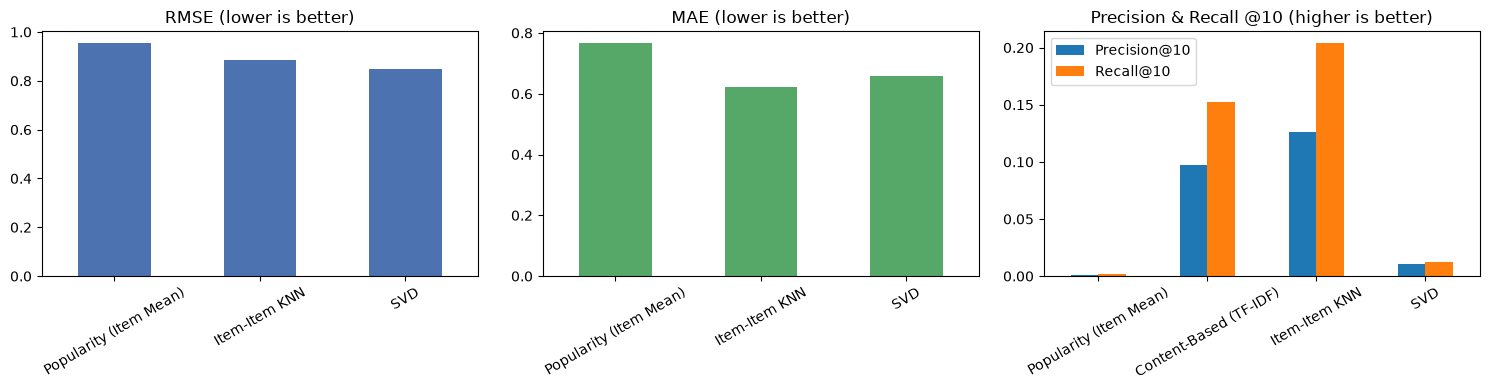

In [16]:
rank_df = pd.DataFrame(rank_results, index=[f"Precision@{K}", f"Recall@{K}"]).T.reset_index()
rank_df.columns = ["Model", f"Precision@{K}", f"Recall@{K}"]

final = rank_df.merge(rating_results, on="Model", how="left").round(4)
final = final[["Model", "RMSE", "MAE", f"Precision@{K}", f"Recall@{K}"]]
final.to_csv("../data/model_comparison.csv", index=False)
print(final.to_string(index=False))

# Chart
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
rr = rating_results.set_index("Model")
rr["RMSE"].plot(kind="bar", ax=ax[0], color="#4c72b0", title="RMSE (lower is better)")
rr["MAE"].plot(kind="bar", ax=ax[1], color="#55a868", title="MAE (lower is better)")
rank_df.set_index("Model")[[f"Precision@{K}", f"Recall@{K}"]].plot(
    kind="bar", ax=ax[2], title=f"Precision & Recall @{K} (higher is better)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../images/06_model_comparison.png", dpi=150)
plt.show()